# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

# Beyond Classical Search

## Optimization

**Numerical minimization of a quadratic.**

* `scipy.optimize.minimize` searches from the initial guess `x_i = 2`.

x = [6.00000025] y =-15.999999999999936


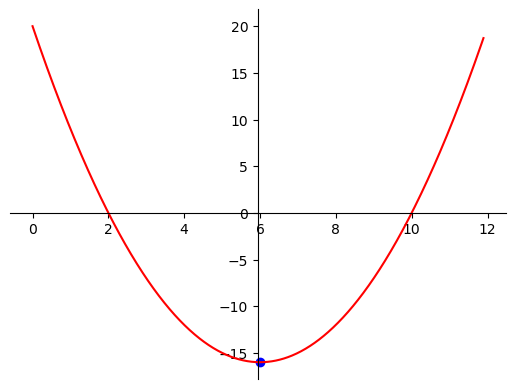

In [ ]:
import scipy.optimize as spo
import matplotlib.pyplot as plt
import numpy as np
def f(x):
  y = (x**2) - (12 * x) + 20
  return y
x_i = 2.0
result = spo.minimize(f, x_i)
if result.success:
  print(f"x = {result.x} y ={result.fun}")
else:
  print("A minimia was not found")
x = np.arange(1000.0)/84.0
y = (x**2) - (12*x) + 20
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.spines['left'].set_position('center')
ax.spines['bottom'].set_position('zero')
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
plt.scatter(result.x, result.fun, color='blue')
plt.plot(x,y, 'r')

* The exact minimum is $(6,-16)$, since $f(x)=(x-6)^2-16$.

**Local and Global Minima:**

* Local minimization starts from two guesses; differential evolution searches the interval $[-2,3]$.
* Orange circles mark local minima, and the red star marks the best candidate from the interval search.

Local minimum: x = -1.0000, f(x) = -0.4167
Local minimum: x = 2.0000, f(x) = -2.6667
Global minimum: x = 2.0000, f(x) = -2.6667


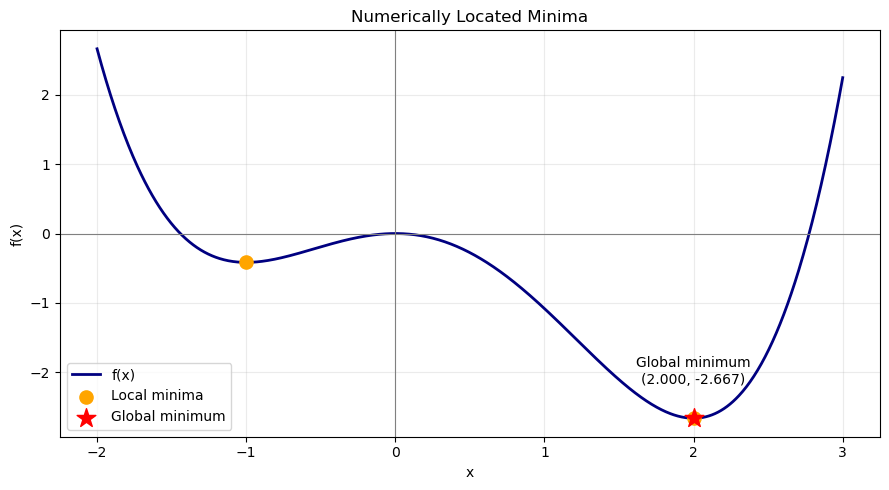

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as spo

f = lambda x: x**4/4 - x**3/3 - x**2
local = [spo.minimize(f, [s]).x.item() for s in [-1.5, 2.5]]
global_x = spo.differential_evolution(f, [(-2, 3)], seed=42).x.item()

x = np.linspace(-2, 3, 1000)
plt.figure(figsize=(9, 5))
plt.plot(x, f(x), color="navy", lw=2, label="f(x)")

for i, xi in enumerate(local):
    plt.scatter(xi, f(xi), c="orange", s=90, zorder=5,
                label="Local minima" if i == 0 else None)
    print(f"Local minimum: x = {xi:.4f}, f(x) = {f(xi):.4f}")

plt.scatter(global_x, f(global_x), c="red", marker="*", s=200,
            zorder=6, label="Global minimum")
plt.annotate(f"Global minimum\n({global_x:.3f}, {f(global_x):.3f})",
             (global_x, f(global_x)), xytext=(0, 25),
             textcoords="offset points", ha="center")
plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("x"); plt.ylabel("f(x)")
plt.title("Numerically Located Minima")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
print(f"Global minimum: x = {global_x:.4f}, f(x) = {f(global_x):.4f}")

* The local minima are $x=-1$ and $x=2$, with values $-5/12$ and $-8/3$.
* Thus $x=2$ is also the global minimum. Numerical search suggests the solution; calculus verifies it.

**A function with three local minima (one as global minima):**

* Three starting guesses help locate different minima of the sixth-degree polynomial.
* Differential evolution searches $[-3.7,2.7]$, and the plot compares the resulting coordinates.

Local minimum: x = -3.0000, f(x) = 8.5500
Local minimum: x = 0.0000, f(x) = 0.0000
Local minimum: x = 2.0000, f(x) = -1.8667
Global minimum: x = 2.0000, f(x) = -1.8667


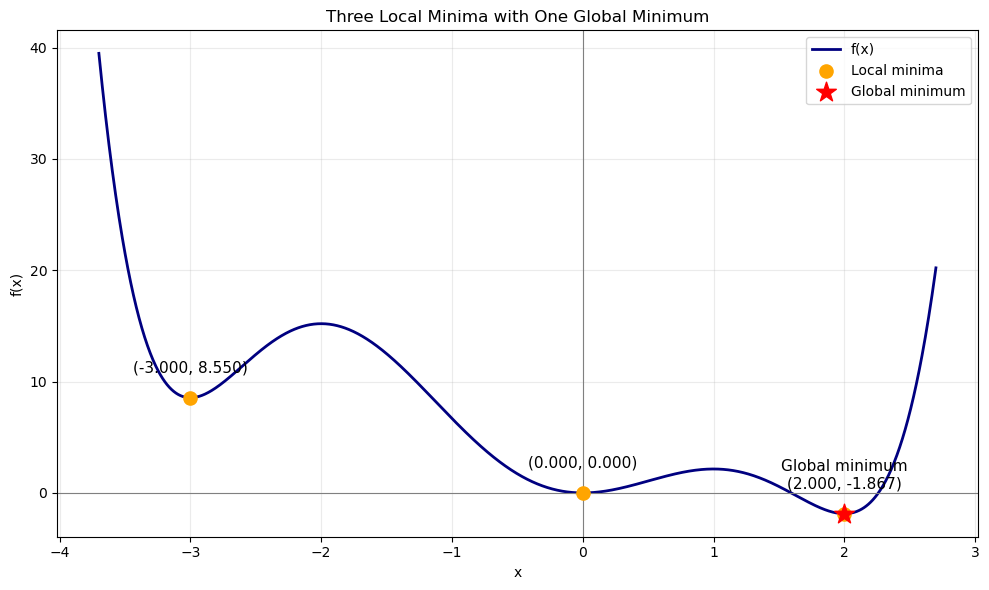

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as spo

f = lambda x: x**6/6 + 2*x**5/5 - 7*x**4/4 - 8*x**3/3 + 6*x**2
local = [spo.minimize(f, [s]).x.item() for s in [-3.2, 0.2, 2.2]]
global_x = spo.differential_evolution(f, [(-3.7, 2.7)], seed=42).x.item()

x = np.linspace(-3.7, 2.7, 1500)
plt.figure(figsize=(10, 6))
plt.plot(x, f(x), color="navy", lw=2, label="f(x)")
plt.scatter(local, f(np.array(local)), c="orange", s=90,
            zorder=5, label="Local minima")
plt.scatter(global_x, f(global_x), c="red", marker="*", s=220,
            zorder=6, label="Global minimum")

for xi in local:
    name = "Global minimum\n" if np.isclose(xi, global_x, atol=1e-3) else ""
    plt.annotate(name + f"({xi:.3f}, {f(xi):.3f})", (xi, f(xi)),
                 xytext=(0, 18), textcoords="offset points",
                 ha="center", fontsize=11)
    print(f"Local minimum: x = {xi:.4f}, f(x) = {f(xi):.4f}")

plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Three Local Minima with One Global Minimum")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
print(f"Global minimum: x = {global_x:.4f}, f(x) = {f(global_x):.4f}")

* The local minima are at $-3$, $0$, and $2$, with values $-63/20$, $0$, and $-116/15$.
* The smallest value occurs at $x=2$, the unique global minimizer.

## Gradient Descent

- **Purpose:** Gradient descent is an iterative method for finding a minimum of a differentiable function.

- **Main idea:** Move in the direction opposite to the gradient, where the function decreases most rapidly locally.

- **Update rule:**
  $$
  x_{t+1} = x_t - \alpha f'(x_t)
  $$
  where:
  - $x_t$ is the current point.
  - $f'(x_t)$ is the derivative at the current point.
  - $\alpha > 0$ is the learning rate.
  - $x_{t+1}$ is the next point.

- **Direction of movement:**
  - If $f'(x_t) > 0$, move to the left.
  - If $f'(x_t) < 0$, move to the right.
  - If $f'(x_t) = 0$, the update does not change the point. This point may be a minimum, a maximum, or another stationary point.

- **Learning rate:**
  - A small learning rate can make convergence slow.
  - A large learning rate can cause oscillation or divergence.
  - A suitable learning rate supports stable progress toward a minimum.

- **Steps:**
  1. Choose an initial point $x_0$ and a learning rate $\alpha$.
  2. Calculate the derivative at the current point.
  3. Update the point using the update rule.
  4. Repeat until a stopping condition is satisfied.

- **Stopping conditions:** Stop when the gradient is sufficiently small, the change between iterations is sufficiently small, or the maximum number of iterations is reached.

- **Example:** For $f(x) = x^2$, the derivative is $f'(x) = 2x$. With $x_0 = 4$ and $\alpha = 0.1$:
  $$
  x_1 = 4 - 0.1(2 \times 4) = 3.2
  $$
  Repeated updates move $x$ toward the global minimum at $x = 0$.

- **Multiple variables:** Replace the derivative with the gradient:
  $$
  \mathbf{x}_{t+1}
  = \mathbf{x}_t - \alpha \nabla f(\mathbf{x}_t)
  $$

- **Limitation:** For nonconvex functions, gradient descent is not guaranteed to find the global minimum. Its outcome can depend on the initial point and learning rate.

$$
\begin{array}{l}
\hline
\text{Algorithm: Gradient Descent (Minimization)}\\
\hline
\text{Input: Differentiable objective } f,\text{ initial point } x_0,\text{ learning rate } \alpha>0,\\
\qquad \text{gradient tolerance } \epsilon>0,\text{ maximum iterations } N\\
\text{Output: Final point } x \text{ and objective value } f(x)\\[4pt]
1.\quad x \gets x_0\\
2.\quad \text{for } k \gets 1 \text{ to } N \text{ do}\\
3.\quad \qquad gradient \gets \nabla f(x)\\
4.\quad \qquad \text{if } \|gradient\|_2 \leq \epsilon \text{ then}\\
5.\quad \qquad \qquad \text{break}\\
6.\quad \qquad \text{end if}\\
7.\quad \qquad x \gets x-\alpha \cdot gradient\\
8.\quad \text{end for}\\
9.\quad \text{return } (x,f(x))\\
\hline
\end{array}
$$

**Gradient descent on a parabola.**

* Starting from `5`, each update moves toward the minimum of $f(x)=(x+5)^2$.
* Its derivative is $2(x+5)$, so the update uses learning rate $0.1$.

A minimum point found as: -4.987620599607146 0.0001532495540865968


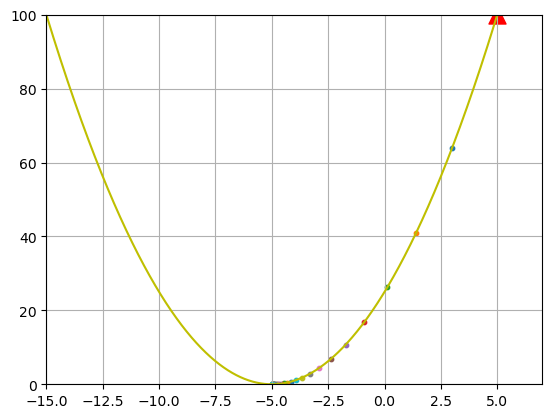

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(-15, 7, 0.01)
plt.plot(x, (x + 5)**2, 'y-')
plt.xlim(-15, 7); plt.ylim(0, 100)
start, y1 = 5.0, 100.0
plt.scatter(start, y1, color='r', marker='^', s=150)
for _ in range(2000):
    start -= 0.2 * (start + 5)
    y0 = (start + 5)**2
    plt.scatter(start, y0, marker='o', s=10)
    if abs(y1 - y0) <= 1e-4: break
    y1 = y0
print('A minimum point found as:', start, y0)
plt.grid()

* The iterates approach the exact minimizer $x=-5$.

**Different starts, different minima.**

* Each run minimizes the same quartic with learning rate `0.05`, but starts at a different coordinate.
* Triangles show starting points; small dots show gradient-descent updates.

Start -1.8: minimum ≈ (-1.0001, -0.4167)
Start -0.3: minimum ≈ (-0.9999, -0.4167)
Start 0.3: minimum ≈ (1.9999, -2.6667)
Start 2.8: minimum ≈ (2.0000, -2.6667)


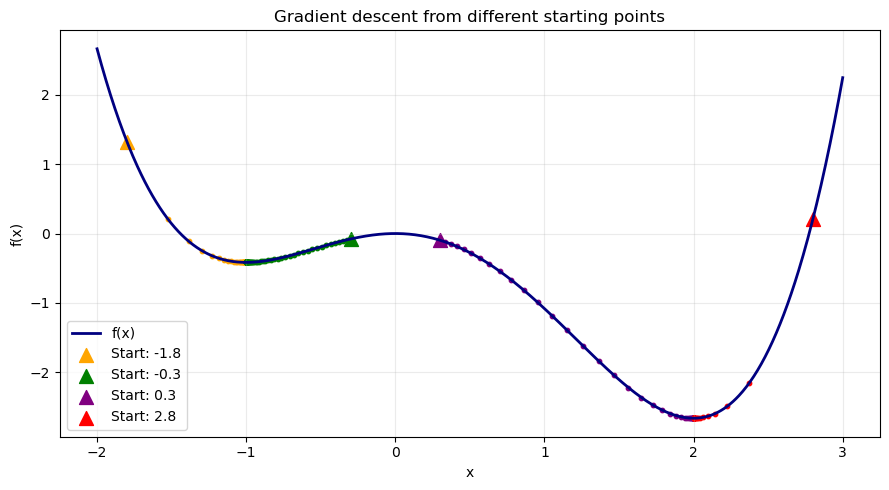

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda x: x**4/4 - x**3/3 - x**2
df = lambda x: x**3 - x**2 - 2*x
x = np.linspace(-2, 3, 1000)
plt.figure(figsize=(9, 5))
plt.plot(x, f(x), color="navy", lw=2, label="f(x)")
for start, color in [(-1.8, "orange"), (-0.3, "green"), (0.3, "purple"), (2.8, "red")]:
    initial, y1 = start, f(start)
    plt.scatter(start, y1, c=color, marker="^", s=100, label=f"Start: {initial}")
    for _ in range(2000):
        start -= 0.05 * df(start)
        y0 = f(start)
        plt.scatter(start, y0, c=color, s=10)
        if abs(y1 - y0) <= 1e-8: break
        y1 = y0
    print(f"Start {initial}: minimum ≈ ({start:.4f}, {y0:.4f})")
plt.xlabel("x"); plt.ylabel("f(x)")
plt.title("Gradient descent from different starting points")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

* Negative starting points approach the local minimum at $-1$; positive starting points approach $2$.
* Gradient descent follows the local slope, so initialization can determine which minimum it reaches.

**Gradient descent with three minima.**

* Four starting points explore different attraction regions of the sixth-degree polynomial.
* The learning rate is `0.005`; the derivative determines the direction and size of each step.

Start -3.5: minimum ≈ (-3.0000, 8.5500)
Start -1: minimum ≈ (-0.0001, 0.0000)
Start 0.5: minimum ≈ (0.0001, 0.0000)
Start 2.5: minimum ≈ (2.0000, -1.8667)


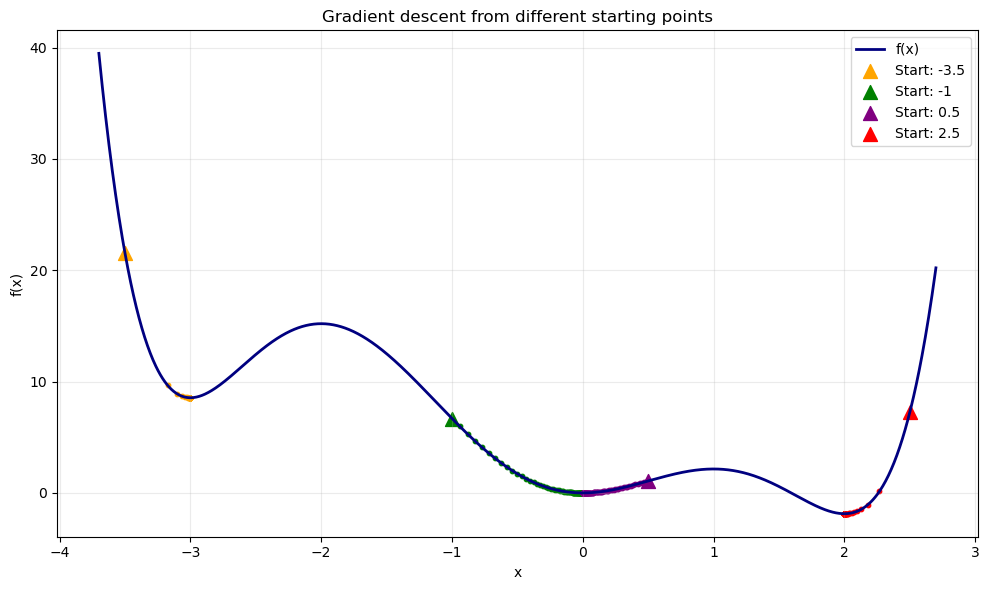

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda x: x**6/6 + 2*x**5/5 - 7*x**4/4 - 8*x**3/3 + 6*x**2
df = lambda x: x**5 + 2*x**4 - 7*x**3 - 8*x**2 + 12*x
x = np.linspace(-3.7, 2.7, 1500)
plt.figure(figsize=(10, 6))
plt.plot(x, f(x), color="navy", lw=2, label="f(x)")
for start, color in [(-3.5, "orange"), (-1, "green"), (0.5, "purple"), (2.5, "red")]:
    initial, y1 = start, f(start)
    plt.scatter(start, y1, c=color, marker="^", s=100, label=f"Start: {initial}")
    for _ in range(2000):
        start -= 0.005 * df(start)
        y0 = f(start)
        plt.scatter(start, y0, c=color, s=10)
        if abs(y1 - y0) <= 1e-8: break
        y1 = y0
    print(f"Start {initial}: minimum ≈ ({start:.4f}, {y0:.4f})")
plt.xlabel("x"); plt.ylabel("f(x)")
plt.title("Gradient descent from different starting points")
plt.grid(alpha=0.25);
plt.legend();
plt.tight_layout()

* Runs can approach $-3$, $0$, or $2$, depending on their starting position.
* Only the minimum at $2$ is global. The printed coordinates are numerical approximations.

**A local minimum of a cubic.**

* The update uses derivative $12x^2-10$ and learning rate `0.001`.
* The algorithm starts at `2` and performs at most 100 steps.

Final point: 0.9896166525017456 -9.01947740601025


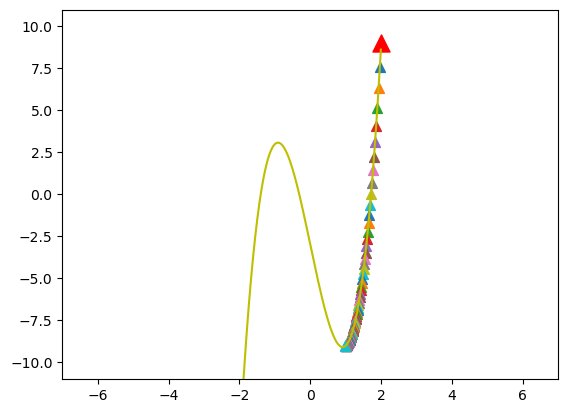

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda x: 4*x**3 - 10*x - 3
x = np.arange(-2, 2, 0.01)
plt.plot(x, f(x), 'y-')
plt.xlim(-7, 7); plt.ylim(-11, 11)
start, y1 = 2.0, f(2)
plt.scatter(start, y1, color='r', marker='^', s=150)
for _ in range(100):
    start -= 0.001 * (12*start**2 - 10)
    y0 = f(start)
    plt.scatter(start, y0, marker='^', s=50)
    if abs(y1 - y0) <= 1e-4: break
    y1 = y0
print('Final point:', start, y0)

* The positive stationary point $x=\sqrt{5/6}$ is a local minimum; the final iterate may still be approaching it.
* There is no global minimum on the real line, because the cubic tends to $-\infty$ as $x\to-\infty$.

## Simulated Annealing

- **Purpose:** Simulated annealing is a randomized optimization method for searching for a global minimum. It does not require derivatives.

- **Main idea:** Randomly propose a nearby solution. Accept improvements and occasionally accept worse solutions to help escape local minima.

- **Candidate generation:**
  $$
  x_{\text{candidate}} = x_t + \epsilon
  $$
  where:
  - $x_t$ is the current point.
  - $\epsilon$ is a random perturbation.
  - $x_{\text{candidate}}$ is the proposed next point.

- **Change in the objective function:**
  $$
  \Delta = f(x_{\text{candidate}}) - f(x_t)
  $$
  - If $\Delta < 0$, the candidate is better.
  - If $\Delta > 0$, the candidate is worse.
  - If $\Delta = 0$, both points have the same objective value.

- **Acceptance rule:**
  $$
  P(\text{accept}) =
  \begin{cases}
  1, & \Delta \leq 0,\\
  e^{-\Delta/T}, & \Delta > 0,
  \end{cases}
  $$
  where $T > 0$ is the temperature. Draw a random number $u$ uniformly from $[0,1)$ and accept the candidate if $u < P(\text{accept})$. Otherwise, keep the current point.

- **Temperature:**
  - A high temperature makes worse solutions more likely to be accepted.
  - A low temperature makes worse solutions less likely to be accepted.
  - Gradually reducing the temperature shifts the search from exploration toward refinement.

- **Cooling rule:** A common choice is geometric cooling:
  $$
  T_{t+1} = \beta T_t, \qquad 0 < \beta < 1.
  $$
  A value of $\beta$ closer to $1$ produces slower cooling and allows more exploration.

- **Steps:**
  1. Choose an initial point $x_0$, an initial temperature $T_0$, and a cooling rate $\beta$.
  2. Generate a random candidate near the current point.
  3. Calculate $\Delta$ and the acceptance probability.
  4. Accept or reject the candidate.
  5. Record the best solution found so far.
  6. Reduce the temperature and repeat.

- **Stopping conditions:** Stop when the temperature falls below a chosen threshold, the maximum number of iterations is reached, or the best solution has not improved for a specified number of iterations.

- **Example:** For $f(x)=x^2$, suppose the current point is $x_t=2$, the candidate is $x_{\text{candidate}}=3$, and $T=10$:
  $$
  \Delta = 3^2 - 2^2 = 5,
  $$
  $$
  P(\text{accept}) = e^{-5/10} \approx 0.607.
  $$
  Although the candidate is worse, it has approximately a $60.7\%$ chance of acceptance. At $T=1$, this probability falls to approximately $0.67\%$.

- **Multiple variables:** Propose a random change to the solution vector:
  $$
  \mathbf{x}_{\text{candidate}}
  = \mathbf{x}_t + \boldsymbol{\epsilon}.
  $$
  The same acceptance rule applies to the change in the objective value.

- **Limitation:** A finite run does not guarantee the global minimum. Performance depends on the initial temperature, cooling schedule, candidate generation, and number of iterations. Return the best solution found, since the final current point may be worse.

$$
\begin{array}{l}
\hline
\text{Algorithm: Simulated Annealing (Minimization)}\\
\hline
\text{Input: Objective } f,\text{ initial solution } x_0,\text{ initial temperature } T_0>0,\\
\qquad \text{cooling factor } 0<\beta<1,\text{ maximum iterations } N\\
\text{Output: Best solution found } x_{\mathrm{best}} \text{ and } f(x_{\mathrm{best}})\\[4pt]
1.\quad x \gets x_0,\quad T \gets T_0\\
2.\quad x_{\mathrm{best}} \gets x\\
3.\quad \text{for } k \gets 1 \text{ to } N \text{ do}\\
4.\quad \qquad x_{\mathrm{new}} \gets \text{randomly sample a feasible neighbor of } x\\
5.\quad \qquad \Delta \gets f(x_{\mathrm{new}})-f(x)\\
6.\quad \qquad p \gets \exp\left(-\dfrac{\max(\Delta,0)}{T}\right)\\
7.\quad \qquad u \gets \mathrm{Uniform}(0,1)\\
8.\quad \qquad \text{if } u<p \text{ then}\\
9.\quad \qquad \qquad x \gets x_{\mathrm{new}}\\
10.\quad \qquad \text{end if}\\
11.\quad \qquad \text{if } f(x)<f(x_{\mathrm{best}}) \text{ then}\\
12.\quad \qquad \qquad x_{\mathrm{best}} \gets x\\
13.\quad \qquad \text{end if}\\
14.\quad \qquad T \gets \beta T\\
15.\quad \text{end for}\\
16.\quad \text{return } (x_{\mathrm{best}},f(x_{\mathrm{best}}))\\
\hline
\end{array}
$$

* `xn` is a random proposal, `delta = f(xn) - f(x)` is its objective change, and `T` is the temperature.
* Improving moves are always accepted. A worse move is accepted with probability $e^{-\Delta/T}$. Temperature falls by 5% per iteration.

            x       f(x)      prob       temp
0    6.000000  33.205845  0.116178  10.000000
1    5.242521  18.856630  1.000000   9.500000
2    4.858207  13.708301  1.000000   9.025000
3    4.790395  12.978290  1.000000   8.573750
4    4.790395  12.978290  0.420937   8.145062
..        ...        ...       ...        ...
195  3.869397   8.319914  0.000000   0.000453
196  3.869397   8.319914  0.000000   0.000430
197  3.869397   8.319914  0.000000   0.000409
198  3.869397   8.319914  0.000000   0.000388
199  3.869397   8.319914  0.000000   0.000369

[200 rows x 4 columns]


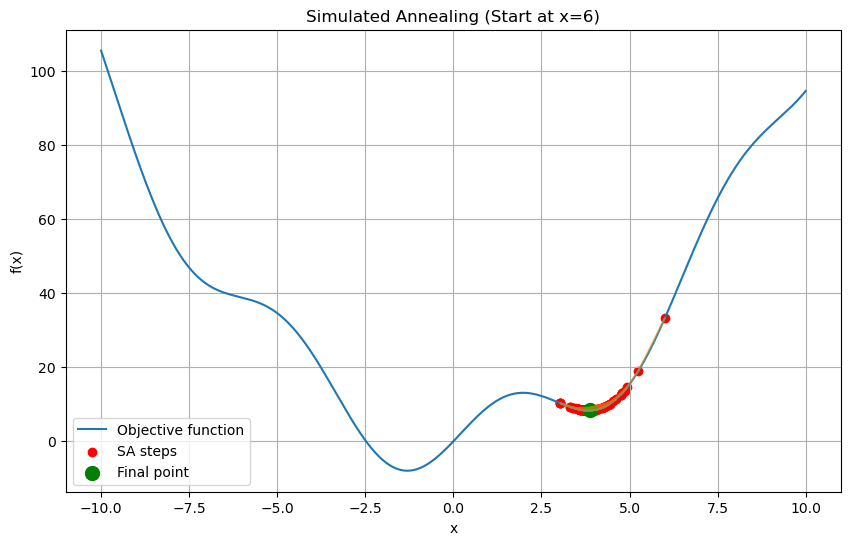

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

f = lambda x: x**2 + 10*np.sin(x)
x, T, history = 6, 10, []
for _ in range(200):
    xn = x + np.random.uniform(-1, 1)
    delta = f(xn) - f(x)
    prob = np.exp(-max(delta, 0)/T)
    if np.random.rand() < prob: x = xn
    history.append([x, f(x), prob, T])
    T *= 0.95
df = pd.DataFrame(history, columns=["x", "f(x)", "prob", "temp"])
print(df)
xs = np.linspace(-10, 10, 400)
plt.figure(figsize=(10, 6))
plt.plot(xs, f(xs), label="Objective function")
plt.scatter(df["x"], df["f(x)"], c="red", label="SA steps")
plt.plot(df["x"], df["f(x)"], c="orange", alpha=0.5)
plt.scatter(x, f(x), c="green", s=100, label="Final point")
plt.title("Simulated Annealing (Start at x=6)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid()

* The table records the state after the acceptance decision, the proposed acceptance probability, and the temperature before cooling. Rejected moves repeat the current state.
* The green marker is the final point, which need not be the best point visited. This example is unseeded, so results can vary.

**Gradient descent vs. simulated annealing.**

* Both methods start at `-1.3`. Gradient descent follows the derivative; annealing can accept uphill moves and escape a local basin.
* `best` records the best annealing point visited, while `s` is its current point. Seed `42` makes the random sequence reproducible.

GD final point: (-1.0000, -0.4167)
SA best point: (1.9998, -2.6667)


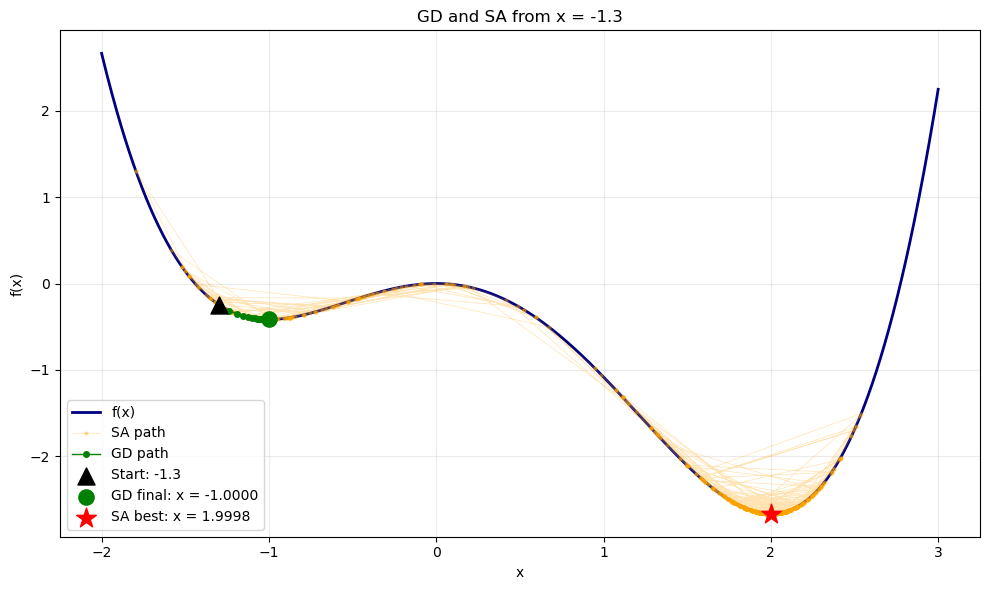

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f = lambda x: x**4/4 - x**3/3 - x**2
df = lambda x: x**3 - x**2 - 2*x
initial = -1.3
g, s, best, T, gd, sa = initial, initial, initial, 1., [initial], [initial]
rng = np.random.default_rng(42)

for _ in range(2000):
    if abs(df(g)) < 1e-6: break
    g -= 0.05*df(g); gd.append(g)

for _ in range(5000):
    candidate = s + rng.uniform(-1, 1); delta = f(candidate)-f(s)
    if delta <= 0 or rng.random() < np.exp(-delta/T): s = candidate
    if f(s) < f(best): best = s
    sa.append(s); T = max(T*0.997, 1e-6)

x, gd, sa = np.linspace(-2, 3, 1000), np.array(gd), np.array(sa)
plt.figure(figsize=(10, 6))
plt.plot(x, f(x), c="navy", lw=2, label="f(x)")
plt.plot(sa, f(sa), "o-", c="orange", ms=2, lw=0.5, alpha=0.3, label="SA path")
plt.plot(gd, f(gd), "o-", c="green", ms=4, lw=1, label="GD path")
plt.scatter(initial, f(initial), c="black", marker="^", s=150, zorder=6, label=f"Start: {initial}")
plt.scatter(g, f(g), c="green", s=120, zorder=5, label=f"GD final: x = {g:.4f}")
plt.scatter(best, f(best), c="red", marker="*", s=220, zorder=7, label=f"SA best: x = {best:.4f}")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title(f"GD and SA from x = {initial}")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
print(f"GD final point: ({g:.4f}, {f(g):.4f})\nSA best point: ({best:.4f}, {f(best):.4f})")

* Compare the green GD endpoint with the red SA best point. The local minimum at $-1$ is worse than the global minimum at $2$.
* This is one illustrative run with different iteration budgets, not a guarantee that annealing always finds the global minimum.

## Genetic Algorithm

- **Purpose:** A genetic algorithm is a randomized optimization method that searches for good solutions through a population of candidates. It does not require derivatives.

- **Main idea:** Evolve a population over several generations through selection, crossover, and mutation.

- **Solution representation:**
  - An **individual**, or **chromosome**, represents one candidate solution.
  - A **gene** represents one component of that solution.
  - A **population** is a collection of individuals.
  - For example, an individual may be a binary string or a vector of real numbers.

- **Fitness evaluation:** Measure the quality of each individual.
  - For minimization, smaller objective values indicate better solutions.
  - For maximization, larger objective values indicate better solutions.
  - The selection method must favor the appropriate objective direction.

- **Selection:** Choose individuals to become parents. Better individuals generally have a higher chance of selection.
  - **Tournament selection:** Randomly choose several individuals and select the best among them.
  - **Roulette-wheel selection:** Select individuals with probabilities proportional to nonnegative fitness scores.

- **Crossover:** Combine information from two parents to create offspring. For real-valued vectors, one possible rule is:
  $$
  \mathbf{x}_{\text{child}}
  = \lambda \mathbf{x}_{\text{parent 1}}
  + (1-\lambda)\mathbf{x}_{\text{parent 2}},
  \qquad 0 \leq \lambda \leq 1.
  $$
  Other representations require suitable crossover operators.

- **Mutation:** Randomly modify genes to introduce diversity. For a real-valued gene, one possible rule is:
  $$
  x_j^{\text{new}} = x_j + \epsilon,
  $$
  where $\epsilon$ is a random perturbation. Mutation occurs according to a chosen probability.

- **Main parameters:**
  - **Population size:** The number of candidate solutions in each generation.
  - **Crossover probability:** How often selected parents undergo crossover.
  - **Mutation probability:** How often random modifications occur.
  - **Number of generations:** How long the population evolves.

- **Elitism:** Preserve one or more of the best individuals in the next generation so that the best solution found is not lost.

- **Steps:**
  1. Generate an initial population.
  2. Evaluate each individual's fitness.
  3. Select parents.
  4. Apply crossover to create offspring.
  5. Apply mutation to the offspring.
  6. Enforce any constraints or variable bounds.
  7. Form the next population, optionally with elitism.
  8. Repeat until a stopping condition is satisfied.

- **Stopping conditions:** Stop when the maximum number of generations is reached, a target objective value is achieved, or the best solution has not improved for a specified number of generations.

- **Example:** To minimize $f(x)=x^2$, consider the population:
  $$
  [-4,\,-1,\,2,\,5].
  $$
  Its objective values are:
  $$
  [16,\,1,\,4,\,25].
  $$
  The individuals $x=-1$ and $x=2$ are better candidates for selection. With $\lambda=0.5$, their offspring is:
  $$
  x_{\text{child}}=0.5(-1)+0.5(2)=0.5,
  $$
  with:
  $$
  f(0.5)=0.25.
  $$
  This offspring is better than both parents, although crossover does not always produce an improvement.

- **Multiple variables:** Represent each individual as a vector:
  $$
  \mathbf{x}=[x_1,x_2,\ldots,x_n].
  $$
  Evaluate the complete vector and use crossover and mutation operators suited to its representation.

- **Limitation:** A finite run does not guarantee the global optimum. Performance depends on the representation, genetic operators, parameter choices, and population diversity. Premature convergence can occur when individuals become too similar.

$$
\begin{array}{l}
\hline
\text{Algorithm: Genetic Algorithm (Minimization)}\\
\hline
\text{Input: Objective } f,\text{ feasible domain } \Omega,\text{ population size } M\geq 2,\\
\qquad \text{crossover probability } p_c,\text{ mutation probability } p_m,\text{ generations } N\\
\text{Output: Best solution found } x_{\mathrm{best}} \text{ and } f(x_{\mathrm{best}})\\[4pt]
1.\quad P \gets \text{randomly initialize } M \text{ feasible individuals in } \Omega\\
2.\quad \text{evaluate } f(x) \text{ for each } x \in P\\
3.\quad \text{for } k \gets 1 \text{ to } N \text{ do}\\
4.\quad \qquad elite \gets \text{the individual in } P \text{ with the smallest } f(x)\\
5.\quad \qquad P_{\mathrm{new}} \gets [elite]\\
6.\quad \qquad \text{while } |P_{\mathrm{new}}|<M \text{ do}\\
7.\quad \qquad \qquad a,b \gets \text{select two parents by tournament selection}\\
8.\quad \qquad \qquad u \gets \mathrm{Uniform}(0,1)\\
9.\quad \qquad \qquad \text{if } u<p_c \text{ then}\\
10.\quad \qquad \qquad \qquad child \gets \mathrm{Crossover}(a,b)\\
11.\quad \qquad \qquad \text{else}\\
12.\quad \qquad \qquad \qquad child \gets \mathrm{Copy}(a)\\
13.\quad \qquad \qquad \text{end if}\\
14.\quad \qquad \qquad v \gets \mathrm{Uniform}(0,1)\\
15.\quad \qquad \qquad \text{if } v<p_m \text{ then}\\
16.\quad \qquad \qquad \qquad child \gets \mathrm{Mutate}(child)\\
17.\quad \qquad \qquad \text{end if}\\
18.\quad \qquad \qquad child \gets \mathrm{RepairToDomain}(child,\Omega)\\
19.\quad \qquad \qquad \text{append } child \text{ to } P_{\mathrm{new}}\\
20.\quad \qquad \text{end while}\\
21.\quad \qquad P \gets P_{\mathrm{new}}\\
22.\quad \qquad \text{evaluate } f(x) \text{ for each } x \in P\\
23.\quad \text{end for}\\
24.\quad x_{\mathrm{best}} \gets \text{the individual in } P \text{ with the smallest } f(x)\\
25.\quad \text{return } (x_{\mathrm{best}},f(x_{\mathrm{best}}))\\
\hline
\end{array}
$$

**A genetic algorithm for continuous optimization.**

* The population contains 40 real numbers. The best ten are retained as parents; 30 children are formed through weighted crossover and Gaussian mutation.
* Clipping keeps candidates inside $[-2,3]$.

Best: x = 1.9997, f(x) = -2.6667


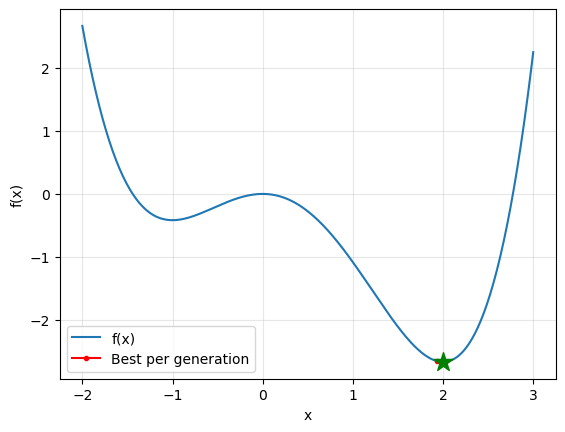

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
f = lambda x: x**4/4 - x**3/3 - x**2
population = rng.uniform(-2, 3, 40)
history = []

for _ in range(100):
    parents = population[np.argsort(f(population))[:10]]
    history.append(parents[0])
    a, b = rng.choice(parents, (2, 30))
    w = rng.random(30)
    children = w*a + (1-w)*b + rng.normal(0, 0.2, 30)
    population = np.r_[parents, np.clip(children, -2, 3)]

best = population[np.argmin(f(population))]
print(f"Best: x = {best:.4f}, f(x) = {f(best):.4f}")

x = np.linspace(-2, 3, 400)
plt.plot(x, f(x), label="f(x)")
plt.plot(history, f(np.array(history)), "ro-", ms=3, label="Best per generation")
plt.scatter(best, f(best), marker="*", s=200, c="green", zorder=5)
plt.xlabel("x"); plt.ylabel("f(x)")
plt.legend();
plt.grid(alpha=0.3)

* Retaining the parents is elitism: the best population objective cannot become worse.
* The red history records the best candidate before each reproduction step. The final green star can be better than the last history entry; global optimality is not guaranteed.

## Knapsack Problem by Genetic Algorithm

**The knapsack problem with binary solutions.**

* Each of six bits indicates whether an item is included. Fitness is total value if weight is at most `50`, and zero otherwise.
* Ranked selection, single-point crossover, and bit-flip mutation produce each new population.

In [ ]:
import random
items = ['A', 'B', 'C', 'D', 'E', 'F']
weights = [15, 3, 2, 5, 9, 20]
values = [15, 7, 10, 5, 8, 17]
max_weight = 50
population_size = 100
generations = 20
mutation_rate = 0.01
def random_population(population_size):
    return [[random.randint(0, 1) for _ in range(len(items))] for _ in range(population_size)]
def fitness(solution):
    total_weight = sum(weights[i] for i in range(len(items)) if solution[i])
    if total_weight > max_weight:
        return 0
    return sum(values[i] for i in range(len(items)) if solution[i])
def crossover(parent1, parent2):
    crossover_point = random.randint(1, len(items) - 1)
    child1 = parent1[:crossover_point] + parent2[crossover_point:]
    child2 = parent2[:crossover_point] + parent1[crossover_point:]
    return child1, child2
def mutate(solution):
    mutated_solution = solution[:]
    for i in range(len(mutated_solution)):
        if random.random() < mutation_rate:
            mutated_solution[i] = 1 - mutated_solution[i]
    return mutated_solution
def genetic_algorithm():
    population = random_population(population_size)
    for _ in range(generations):
        population = sorted(population, key=lambda x: fitness(x), reverse=True)
        new_population = []
        for i in range(population_size // 2):
            parent1, parent2 = population[i], population[i + 1]
            child1, child2 = crossover(parent1, parent2)
            new_population.extend([mutate(child1), mutate(child2)])
        population = new_population
    return max(population, key=lambda x: fitness(x))
best_solution = genetic_algorithm()

print("The best combinations is::", best_solution)
print("The total possible value of the items:", sum(values[i] for i in range(len(items)) if best_solution[i]))
print("The total possible weight of the items:", sum(weights[i] for i in range(len(items)) if best_solution[i]))

The best combinations is:: [1, 1, 1, 0, 1, 1]
The total possible value of the items: 57
The total possible weight of the items: 49


* The exact optimum is `[1, 1, 1, 0, 1, 1]`: weight `49` and value `57`. Compare the returned solution with this benchmark.

**The traveling salesman problem:**

* A route is a permutation of city indices. Its distance includes the return from the last city to the first.
* Tournament selection favors short tours; crossover keeps each city exactly once, and mutation swaps two cities.

Seed 0, Generation 100: 206.6348
Seed 0, Generation 200: 205.4115
Seed 0, Generation 300: 205.4115
Seed 0: 366 generations, distance = 205.4115
Seed 1, Generation 100: 205.8591
Seed 1, Generation 200: 205.6391
Seed 1, Generation 300: 205.1241
Seed 1, Generation 400: 205.1241
Seed 1: 470 generations, distance = 205.1241
Seed 2, Generation 100: 206.6869
Seed 2, Generation 200: 205.8862
Seed 2, Generation 300: 205.0535
Seed 2, Generation 400: 205.0535
Seed 2: 447 generations, distance = 205.0535
Seed 3, Generation 100: 204.6013
Seed 3, Generation 200: 204.4499
Seed 3, Generation 300: 204.4499
Seed 3: 305 generations, distance = 204.4499
Seed 4, Generation 100: 203.9410
Seed 4, Generation 200: 203.5911
Seed 4, Generation 300: 203.5911
Seed 4: 321 generations, distance = 203.5911

Best route found: [15, 10, 4, 1, 0, 2, 3, 5, 6, 18, 11, 16, 14, 19, 8, 17, 20, 13, 9, 12, 7]
Best distance found: 203.5911


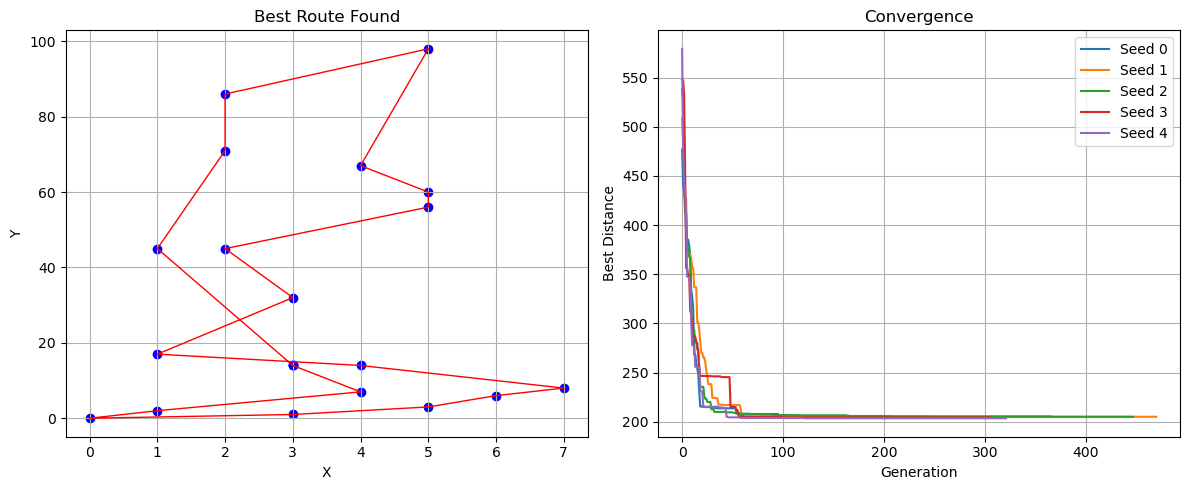

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

cities = np.array([
    (0,0), (1,2), (3,1), (5,3), (4,7), (6,6), (7,8),
    (3,14), (5,60), (2,71), (3,14), (1,17), (1,45),
    (2,86), (2,45), (3,14), (3,32), (4,67), (4,14),
    (5,56), (5,98)
])
distances = np.linalg.norm(cities[:, None] - cities[None, :], axis=2)
distance = lambda route: distances[route, np.roll(route, -1)].sum()

def ga(seed, size=50, generations=1000, patience=200):
    rng = random.Random(seed)
    population = [rng.sample(range(len(cities)), len(cities)) for _ in range(size)]
    best = min(population, key=distance).copy()
    reference, stale, history = distance(best), 0, [distance(best)]
    for generation in range(1, generations + 1):
        new = [best.copy()]  # Elitism
        while len(new) < size:
            p1, p2 = sorted(rng.sample(population, 5), key=distance)[:2]
            a, b = sorted(rng.sample(range(len(cities)), 2))
            segment = p1[a:b + 1]
            remaining = [city for city in p2 if city not in segment]
            child = remaining[:a] + segment + remaining[a:]
            if rng.random() < 0.1:
                i, j = rng.sample(range(len(cities)), 2)
                child[i], child[j] = child[j], child[i]
            new.append(child)
        population = new
        best = min(population, key=distance).copy()
        score = distance(best)
        stale = 0 if reference - score > 1e-6 else stale + 1
        if stale == 0: reference = score
        history.append(score)
        if generation % 100 == 0:
            print(f"Seed {seed}, Generation {generation}: {score:.4f}")
        if stale >= patience: break
    print(f"Seed {seed}: {generation} generations, distance = {score:.4f}")
    return best, history

results = [ga(seed) for seed in range(5)]
best, _ = min(results, key=lambda result: distance(result[0]))
print("\nBest route found:", best)
print(f"Best distance found: {distance(best):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
path = cities[best + [best[0]]]
axes[0].plot(path[:, 0], path[:, 1], "r-", lw=1)
axes[0].scatter(*cities.T, color="blue")
axes[0].set(xlabel="X", ylabel="Y", title="Best Route Found")
for seed, (_, history) in enumerate(results):
    axes[1].plot(history, label=f"Seed {seed}")
axes[1].set(xlabel="Generation", ylabel="Best Distance", title="Convergence")
axes[1].legend()
for ax in axes: ax.grid(True)
plt.tight_layout()

* The stored best route is the shortest encountered after reproduction, not a proven global optimum. Identical coordinates still represent separate indexed cities.
* The call runs 10,000 generations and prints progress for every generation. Both random generators are unseeded, so the route can vary.